# 02. Exploratory Data Analysis

CRISP-DM phase: Data understanding

This notebook explores the cleaned dataset from `01_data_understanding_and_cleaning.ipynb`. It defines the 3-level target, looks at how the levels relate to the other variables, and ends with the PHQ-2 baseline that the models have to beat. The relationships found are associations and do not establish causes.

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
#necessary imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import recall_score, precision_score

#showing the full category names in tables
pd.set_option('display.max_colwidth', None)

### 1.2 Loading the Cleaned Dataset

The cleaned file has 19,251 students. The cleaning steps are explained in notebook 01.

In [2]:
#loading the cleaned dataset
df = pd.read_csv("../data/zenodo_clean.csv")

In [3]:
#shape of the dataset
df.shape

(19251, 85)

## 2. Target Variable Definition

The app gives one of three results, so the PHQ-9 total is turned into a target column called `level`, using the standard PHQ-9 bands:

- 0 = okay (PHQ-9 total 0 to 4)
- 1 = mild (5 to 9)
- 2 = moderate or worse (10 to 27)

A total of 10 or more is the usual cut-off for moderate or worse depression. The standard bands above 10 (moderate, moderately severe and severe) are joined into one level because there are few students in them, for example only 87 students score 20 or more.

### 2.1 Creating the Three Screening Levels

The next cells create `level` and count the students in each level, first as numbers and then as percentages.

In [4]:
#creating the three levels: 0 = okay, 1 = mild, 2 = moderate or worse
df['level'] = pd.cut(df['phq_total'], bins=[-1, 4, 9, 27], labels=[0, 1, 2]).astype(int)
df['level'].value_counts().sort_index()

level
0    11933
1     6034
2     1284
Name: count, dtype: int64

In [5]:
#percentage in each level
df['level'].value_counts(normalize=True).sort_index() * 100

level
0    61.986390
1    31.343826
2     6.669783
Name: proportion, dtype: float64

### 2.2 Visualising the Class Balance

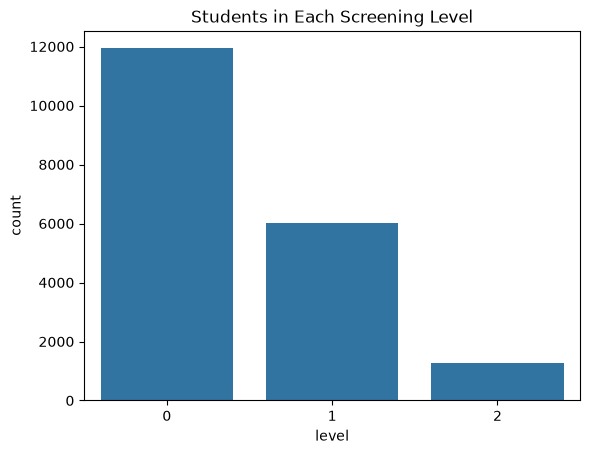

In [6]:
#visualising the three levels
sns.countplot(x='level', data=df)
plt.title('Students in Each Screening Level')
plt.show()

#### Observation

62.0% of students are okay (11,933), 31.3% are mild (6,034) and 6.7% are moderate or worse (1,284). Level 0 has about nine times as many students as level 2, so the data is imbalanced. A model that always predicted level 0 would be about 62% accurate but would never find a mild or a moderate or worse student, so accuracy alone is misleading. For a screening tool, missing a level 2 student is the most serious mistake, so the models will be judged on recall for each level and on macro F1 (which gives each level the same weight), and the splits will be stratified.

### 2.3 Leakage Rule

The label comes from the PHQ-9 total, which is the sum of all nine PHQ-9 questions. If a model could see questions 3 to 9 or the total, it could work out the label directly. This is called data leakage, and the results would look much better than they would be in the real app, where those questions are not asked. The features can therefore only be PHQ-9 questions 1 and 2 (the PHQ-2) and the GAD-7, ISI and PSS questions. The columns `phq_total` and `phq_q3` to `phq_q9` are never used as features.

## 3. Exploratory Data Analysis

This section looks at how PHQ-9 scores are distributed, how the three levels relate to gender, drinking, education, smoking and age, how anxiety, insomnia and stress differ between the levels, and which individual questions are most related to the PHQ-9 total. It ends with the PHQ-2 baseline. The aim is to understand the data and guide feature selection.

### 3.1 Distribution of PHQ-9 Total Scores

The histogram shows one bar for each possible PHQ-9 total (0 to 27). The dashed red lines mark where level 1 starts (5) and where level 2 starts (10).

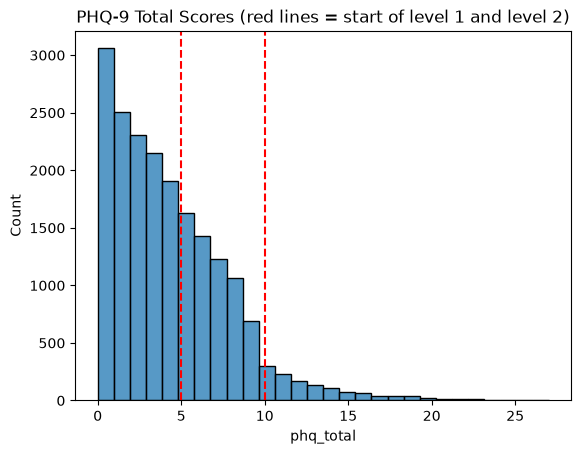

In [7]:
#distribution of phq-9 total scores
sns.histplot(df['phq_total'], bins=28)
plt.axvline(5, color='red', linestyle='--')
plt.axvline(10, color='red', linestyle='--')
plt.title('PHQ-9 Total Scores (red lines = start of level 1 and level 2)')
plt.show()

#### Observation

The distribution is strongly right-skewed. The most common score is 0 (3,058 students), counts fall steadily as scores rise, and 70.5% of students score 5 or less. The level cut-offs are not at natural gaps in the data: 1,911 students score 4 and 1,633 score 5, and 688 score 9 against 304 who score 10. Students on either side of a line have very similar symptoms, so students close to a cut-off will be the hardest to classify. Scores of 20 or more are rare (87 students).

### 3.2 Levels by Gender

The first table counts the students in each level for each gender. The second table shows the same counts as percentages of each gender (each row adds up to 100). The chart shows the percentages as stacked bars.

In [8]:
#number of students in each level by gender
pd.crosstab(df['gender'], df['level'])

level,0,1,2
gender,,,
female,7820,4071,800
male,4113,1963,484


In [9]:
#percentage of each gender in each level
(pd.crosstab(df['gender'], df['level'], normalize='index') * 100).round(1)

level,0,1,2
gender,,,
female,61.6,32.1,6.3
male,62.7,29.9,7.4


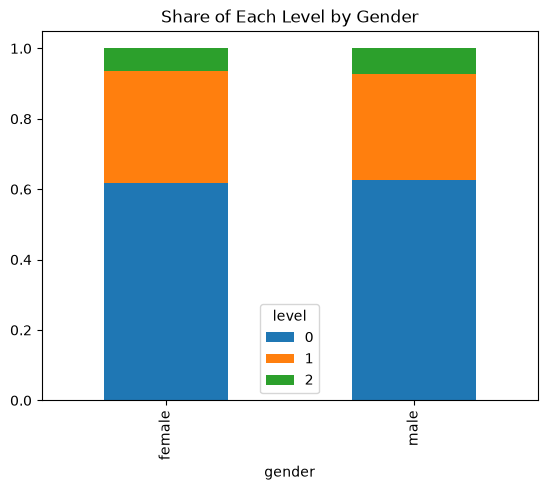

In [10]:
#levels by gender as stacked bars
pd.crosstab(df['gender'], df['level'], normalize='index').plot(kind='bar', stacked=True)
plt.title('Share of Each Level by Gender')
plt.show()

#### Observation

Among female students 61.6% are okay, 32.1% are mild and 6.3% are moderate or worse (800 of 12,691). Among male students the shares are 62.7%, 29.9% and 7.4% (484 of 6,560). The gap is about two percentage points or less in every level, so gender separates the levels only weakly. This is an association in this sample and does not explain why the rates differ. Men are the smaller group (34% of students), so their rates are estimated less precisely. Gender is unlikely to drive the model's predictions.

### 3.3 Levels by Drinking Habits

The tables show the number and the percentage of students in each level for each drinking category. Tables are used instead of a plot because the category names are long.

In [11]:
#number of students in each level by drinking habit
pd.crosstab(df['drinking'], df['level'])

level,0,1,2
drinking,,,
current regular drinker (more than once a week),65,73,54
"drank in the past (more than once a week), but not in the past year",118,100,29
drinks occasionally (less than once a week),3519,2132,587
never drinks,8231,3729,614


In [12]:
#percentage of each drinking group in each level
(pd.crosstab(df['drinking'], df['level'], normalize='index') * 100).round(1)

level,0,1,2
drinking,,,
current regular drinker (more than once a week),33.9,38.0,28.1
"drank in the past (more than once a week), but not in the past year",47.8,40.5,11.7
drinks occasionally (less than once a week),56.4,34.2,9.4
never drinks,65.5,29.7,4.9


#### Observation

The share of okay students falls as drinking increases, from 65.5% among students who never drink to 33.9% among current regular drinkers. The share of moderate or worse students rises from 4.9% to 28.1% (54 of 192 students), nearly six times as high. The mild share changes less (29.7% to 38.0%). This is an association and not evidence that drinking causes depression: students may drink to cope with low mood, and other factors may affect both. The highest-risk groups are small, and 1,201 of the 1,284 moderate or worse students (93.5%) never drink or drink only occasionally, so drinking cannot identify most cases and is at best a weak supporting feature.

### 3.4 Levels by Education Level

The tables show the number and the percentage of students in each level for each education level.

In [13]:
#number of students in each level by education level
pd.crosstab(df['education'], df['level'])

level,0,1,2
education,,,
associate degree,651,304,86
bachelor's degree,10943,5611,1163
doctorate degree,14,3,2
master's degree,325,116,33


In [14]:
#percentage of each education group in each level
(pd.crosstab(df['education'], df['level'], normalize='index') * 100).round(1)

level,0,1,2
education,,,
associate degree,62.5,29.2,8.3
bachelor's degree,61.8,31.7,6.6
doctorate degree,73.7,15.8,10.5
master's degree,68.6,24.5,7.0


#### Observation

The share of moderate or worse students is 8.3% among associate-degree students (86 of 1,041), 6.6% among bachelor's students (1,163 of 17,717), 7.0% among master's students (33 of 474) and 10.5% among doctorate students (2 of 19). Okay students make up 62.5% of the associate group and 61.8% of the bachelor's group, and a larger share of the master's group (68.6%). The differences are small, and the doctorate group is too small to draw conclusions from (19 students). Bachelor's students make up 92% of the sample, so education level separates the levels only weakly.

### 3.5 Levels by Smoking Habits

The tables show the number and the percentage of students in each level for each smoking category.

In [15]:
#number of students in each level by smoking habit
pd.crosstab(df['smoking'], df['level'])

level,0,1,2
smoking,,,
current smoker (cumulative smoking >10 packs),218,148,82
"former smoker (cumulative smoking >10 packs), but not in the past year",72,51,28
never smokes,11195,5522,1079
occasional smoker (cumulative smoking <10 packs),448,313,95


In [16]:
#percentage of each smoking group in each level
(pd.crosstab(df['smoking'], df['level'], normalize='index') * 100).round(1)

level,0,1,2
smoking,,,
current smoker (cumulative smoking >10 packs),48.7,33.0,18.3
"former smoker (cumulative smoking >10 packs), but not in the past year",47.7,33.8,18.5
never smokes,62.9,31.0,6.1
occasional smoker (cumulative smoking <10 packs),52.3,36.6,11.1


#### Observation

Smokers are less often okay (48.7% of current smokers and 47.7% of former smokers, against 62.9% of students who never smoke). The share of moderate or worse students is 6.1% among non-smokers, 11.1% among occasional smokers, 18.3% among current smokers (82 of 448) and 18.5% among former smokers (28 of 151), about three times the rate of non-smokers. As with drinking, this is an association and not evidence that smoking causes depression. The smoking groups are small, and 1,079 of the 1,284 moderate or worse students (84%) have never smoked, so smoking cannot identify most cases and is at best a weak supporting feature.

### 3.6 Age and the Levels

The boxplot compares the ages of students in the three levels. The ages are then grouped into bands so the level shares can be compared across the bands.

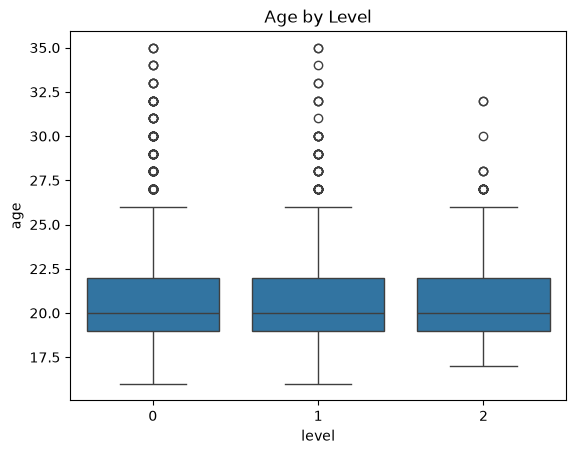

In [17]:
#comparing age between the three levels
sns.boxplot(x='level', y='age', data=df)
plt.title('Age by Level')
plt.show()

In [18]:
#mean and median age in each level
df.groupby('level')['age'].agg(['mean', 'median']).round(1)

,mean,median
level,,
0,20.6,20.0
1,20.5,20.0
2,20.7,20.0


In [19]:
#putting ages into groups
df['age_group'] = pd.cut(df['age'], bins=[15, 18, 20, 22, 25, 35], labels=['16-18', '19-20', '21-22', '23-25', '26-35'])
df['age_group'].value_counts()

age_group
19-20    8351
21-22    5789
23-25    2475
16-18    2301
26-35     335
Name: count, dtype: int64

In [20]:
#percentage of each age group in each level
(pd.crosstab(df['age_group'], df['level'], normalize='index') * 100).round(1)

level,0,1,2
age_group,,,
16-18,63.0,31.7,5.3
19-20,61.3,32.1,6.6
21-22,61.6,31.4,7.0
23-25,63.4,29.6,7.0
26-35,67.8,22.4,9.9


#### Observation

The three levels have almost the same ages. The mean age is 20.6 for level 0, 20.5 for level 1 and 20.7 for level 2, and all three have a median of 20. By age band, the share of moderate or worse students rises gently from 5.3% (16-18) to 6.6% (19-20), 7.0% (21-22) and 7.0% (23-25), and reaches 9.9% for ages 26-35. The oldest band is small (335 students, 33 of them level 2), so its higher rate is less reliable. Age is only weakly related to the levels in this sample and is unlikely to drive the model's predictions.

### 3.7 Anxiety, Insomnia and Stress by Level

The boxplots compare GAD-7 (anxiety), ISI (insomnia) and PSS (perceived stress) totals between the three levels. If the scores differ clearly between the levels, these questionnaires are useful for predicting the level and could replace the PHQ-9 questions that cannot be used. The tables below give the mean, median and quartiles behind the boxplots.

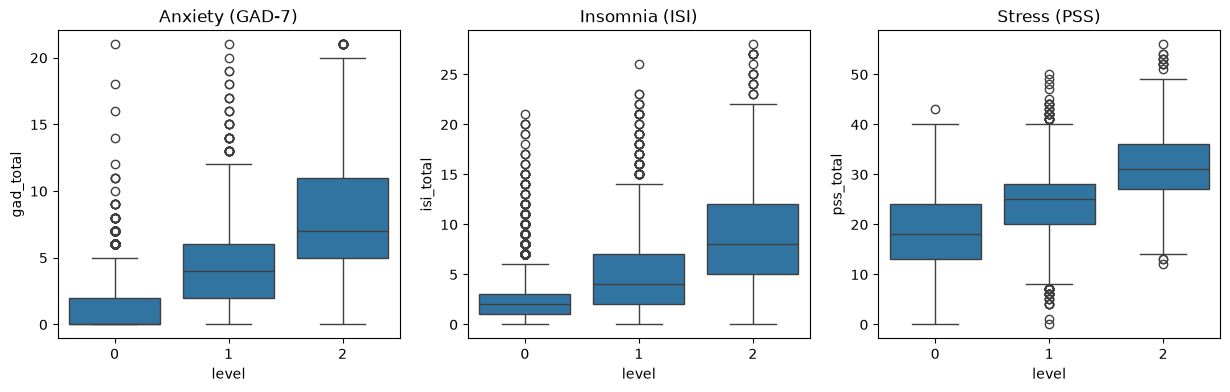

In [21]:
#comparing anxiety, insomnia and stress scores between the three levels
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x='level', y='gad_total', data=df, ax=ax[0])
sns.boxplot(x='level', y='isi_total', data=df, ax=ax[1])
sns.boxplot(x='level', y='pss_total', data=df, ax=ax[2])
ax[0].set_title('Anxiety (GAD-7)')
ax[1].set_title('Insomnia (ISI)')
ax[2].set_title('Stress (PSS)')
plt.show()

In [22]:
#mean score in each level
df.groupby('level')[['gad_total', 'isi_total', 'pss_total']].mean().round(1)

,gad_total,isi_total,pss_total
level,,,
0,1.0,2.2,18.3
1,3.9,4.8,24.0
2,8.2,9.0,31.8


In [23]:
#median score in each level
df.groupby('level')[['gad_total', 'isi_total', 'pss_total']].median()

,gad_total,isi_total,pss_total
level,,,
0,0.0,2.0,18.0
1,4.0,4.0,25.0
2,7.0,8.0,31.0


In [24]:
#lower quartile (25%) in each level
df.groupby('level')[['gad_total', 'isi_total', 'pss_total']].quantile(0.25)

,gad_total,isi_total,pss_total
level,,,
0,0.0,1.0,13.0
1,2.0,2.0,20.0
2,5.0,5.0,27.0


In [25]:
#upper quartile (75%) in each level
df.groupby('level')[['gad_total', 'isi_total', 'pss_total']].quantile(0.75)

,gad_total,isi_total,pss_total
level,,,
0,2.0,3.0,24.0
1,6.0,7.0,28.0
2,11.0,12.0,36.0


#### Observation

Scores rise with each level on all three scales. The median anxiety score is 0 for level 0, 4 for level 1 and 7 for level 2. The median insomnia score is 2, 4 and 8, and the median stress score is 18, 25 and 31 (means: anxiety 1.0, 3.9 and 8.2, insomnia 2.2, 4.8 and 9.0, stress 18.3, 24.0 and 31.8). Level 0 and level 2 are clearly apart: the lower quartile of level 2 (5, 5 and 27) is above the upper quartile of level 0 (2, 3 and 24). Level 1 sits in the middle and overlaps with level 2, because its upper quartile (6, 7 and 28) is above the lower quartile of level 2. No single scale separates the three levels, and mild against moderate or worse will be the hardest split, which is why the model will combine several questions.

### 3.8 Correlations Between Questionnaire Totals

The heatmap shows the Pearson correlation between the four questionnaire totals, from -1 to 1. It shows how closely the scales move together. Strongly correlated predictors carry overlapping information.

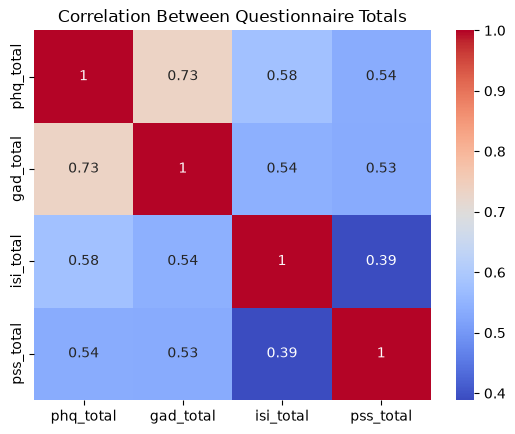

In [26]:
#correlation heatmap of the four totals
sns.heatmap(df[['phq_total', 'gad_total', 'isi_total', 'pss_total']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Between Questionnaire Totals')
plt.show()

#### Observation

All four totals are positively correlated. PHQ-9 correlates most strongly with GAD-7 (0.73) and moderately with ISI (0.58) and PSS (0.54), while the correlations among the other three are 0.54 (GAD-7 and ISI), 0.53 (GAD-7 and PSS) and 0.39 (ISI and PSS). This fits the common co-occurrence of depression, anxiety, poor sleep and stress, and explains why items from the other questionnaires can help predict the PHQ-9 level. No pair is above 0.73, so the scales are related but not interchangeable, and each adds some separate information. Overlap between predictors should be checked again at item level when the features are selected.

### 3.9 Individual Questions and PHQ-9

To decide which questions should go into the screening app, each candidate question is correlated with the PHQ-9 total. The candidates are PHQ-9 questions 1 and 2, all seven GAD-7 questions, all seven ISI questions and all 14 PSS questions. PHQ-9 questions 3 to 9 are left out because they make up the target (see the leakage rule in Section 2.3). The bar chart ranks the questions from strongest to weakest correlation.

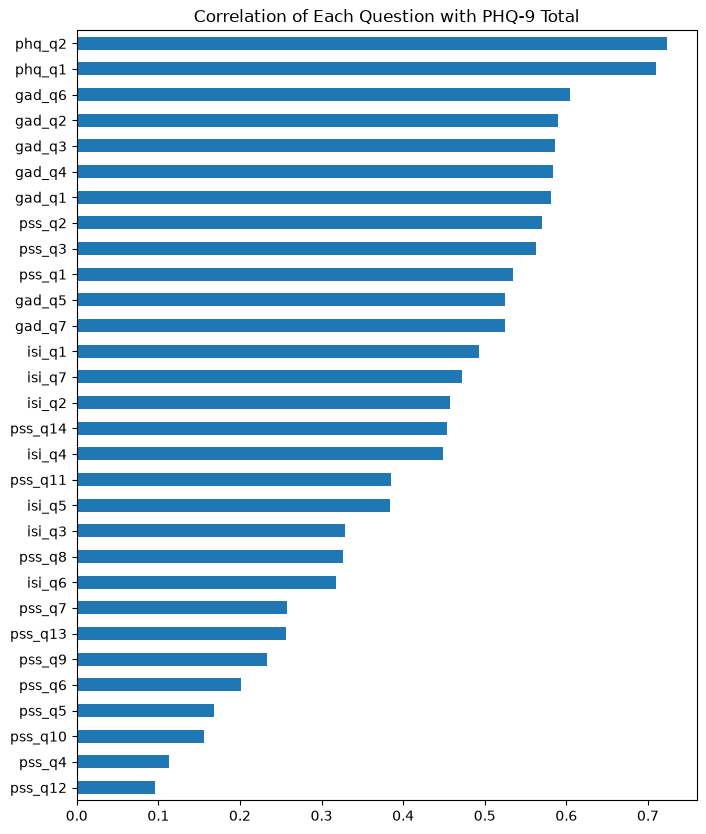

In [27]:
#questions we are allowed to use (phq q3-q9 are left out because they make up the answer)
phq_items = ['phq_q1', 'phq_q2']
gad_items = ['gad_q1', 'gad_q2', 'gad_q3', 'gad_q4', 'gad_q5', 'gad_q6', 'gad_q7']
isi_items = ['isi_q1', 'isi_q2', 'isi_q3', 'isi_q4', 'isi_q5', 'isi_q6', 'isi_q7']
pss_items = ['pss_q1', 'pss_q2', 'pss_q3', 'pss_q4', 'pss_q5', 'pss_q6', 'pss_q7', 'pss_q8', 'pss_q9', 'pss_q10', 'pss_q11', 'pss_q12', 'pss_q13', 'pss_q14']
items = phq_items + gad_items + isi_items + pss_items

corr = df[items + ['phq_total']].corr()['phq_total'].drop('phq_total').sort_values(ascending=False)

corr.plot(kind='barh', figsize=(8, 10))
plt.title('Correlation of Each Question with PHQ-9 Total')
plt.gca().invert_yaxis()
plt.show()

#### Observation

`phq_q2` (0.72) and `phq_q1` (0.71) correlate most strongly with the PHQ-9 total, followed by the GAD-7 questions (about 0.53 to 0.60, highest `gad_q6`), three PSS questions (`pss_q2` 0.57, `pss_q3` 0.56, `pss_q1` 0.53) and the ISI questions (0.32 to 0.49, highest `isi_q1`). Many PSS questions are weak, with `pss_q12` (0.10), `pss_q4` (0.11) and `pss_q10` (0.16) at the bottom. This supports a short questionnaire built from the two PHQ-2 questions plus a few of the strongest GAD-7, PSS and ISI questions, instead of all 30 candidates, since the weak questions add length without much signal. Two cautions apply: `phq_q1` and `phq_q2` are part of the PHQ-9 total, so some of their correlation is built in, and questions are assessed one at a time, so questions from the same questionnaire partly overlap. The selection itself is made in `03_preprocessing.ipynb`.

### 3.10 PHQ-2 Baseline

The PHQ-2 is the sum of the first two PHQ-9 questions, and a score of 3 or more is the standard rule for a positive screen. The PHQ-2 is a yes/no rule, so it cannot tell level 0 from level 1. It is therefore compared with the models only on catching level 2 (moderate or worse) against everyone else. The first table shows the rule against all three levels (rows: False means a PHQ-2 score below 3, True means 3 or more). The next cell calculates recall and precision for level 2.

In [28]:
#phq-2 score = first two phq questions
df['phq2'] = df['phq_q1'] + df['phq_q2']

#phq-2 rule: score of 3 or more = possible level 2
pd.crosstab(df['phq2'] >= 3, df['level'])

level,0,1,2
phq2,,,
False,11891,5576,472
True,42,458,812


In [29]:
#recall and precision of the phq-2 rule for level 2 (level 2 against the rest)
print(round(recall_score(df['level'] == 2, df['phq2'] >= 3), 3))
print(round(precision_score(df['level'] == 2, df['phq2'] >= 3), 3))

0.632
0.619


#### Interpretation

The PHQ-2 rule flags 1,312 students (6.8% of the sample). It catches 812 of the 1,284 level 2 students (recall 63.2%) and misses 472 (36.8%). Of the 1,312 flagged students, 812 are level 2 (precision 61.9%), 458 are mild and only 42 are okay. So most of the false alarms are mild students, and the rule mainly confuses mild with moderate or worse. This is the baseline for the project: a model needs to find more of the 472 missed level 2 students (recall above 63%) without a large rise in false alarms. Unlike the rule, a model can also separate level 0 from level 1.

## 4. Summary of EDA Findings

- Data quality: After cleaning, the dataset has 19,251 students and no missing values or duplicate rows. The sample is young (mean age 20.6), mostly female (65.9%) and mostly bachelor's students (92.0%), so results should be generalised with care.
- Class imbalance: 62.0% of students are okay (level 0), 31.3% are mild (level 1) and only 6.7% (1,284) are moderate or worse (level 2). Accuracy is misleading (always predicting level 0 gives about 62%), so the models will be judged on per-class recall and macro F1, with stratified splits and class weights.
- PHQ-9 distribution: Scores are strongly right-skewed with a mode of 0. The cut-offs fall inside the falling curve (1,911 students score 4 and 1,633 score 5; 688 score 9 and 304 score 10), so students near a cut-off will be difficult to classify.
- Demographics and lifestyle: Gender differs little (6.3% level 2 for women, 7.4% for men). The share of moderate or worse students rises with drinking, from 4.9% for non-drinkers to 28.1% for current regular drinkers, and smoking shows a similar pattern (6.1% for non-smokers against about 18% for current and former smokers), but these groups are small and most level 2 students drink little or not at all and have never smoked. These are associations only.
- Education and age differ little (level 2 shares of 6.6% to 8.3% across the main education levels, and 5.3% to 7.0% for ages 16 to 25).
- Related questionnaires: Anxiety, insomnia and stress scores rise with each level (median GAD-7 0, 4 and 7; ISI 2, 4 and 8; PSS 18, 25 and 31). Level 2 is clearly separated from level 0, but level 1 overlaps with level 2, so several questions will be combined. The totals correlate with PHQ-9 at 0.73 (GAD-7), 0.58 (ISI) and 0.54 (PSS).
- Candidate questions: The two PHQ-2 questions (0.71 and 0.72), the GAD-7 questions and a few PSS and ISI questions correlate most with the PHQ-9 total, while many PSS questions are weak. This supports a short questionnaire. `phq_total` and `phq_q3` to `phq_q9` are excluded to avoid data leakage.
- Baseline to beat: The PHQ-2 rule catches 812 of 1,284 level 2 students (recall 63.2%, precision 61.9%), misses 472, and most of its false alarms are mild students. The models will be judged on whether they improve recall for level 2, and on how well they separate all three levels, compared with this rule.

The next notebook, `03_preprocessing.ipynb`, selects the features and creates the training and test sets.